# 3. Count Models: Workplace Accidents

**Question.** What drives the number of workplace accidents across five factories, and is Poisson regression the right model?

**Data.** 10,000 workers (`data/workplace_accidents.csv`): age, safety test score (0 to 10), factory, chemical handled, years in the factory, and the total number of accidents over those years. Synthetic course data.

**Approach.** Because workers have been exposed for different lengths of time, the models include `log(years in factory)` as an **offset**, so they describe the accident rate per year rather than the raw count. Poisson regression is fitted first, its assumptions are tested four ways, and a negative binomial model is fitted when they fail.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore")
DATA = Path("../data"); FIG = Path("../images"); FIG.mkdir(exist_ok=True)
BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#c9c8c2", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#ecebe7", "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left",
})
from scipy.stats import chi2

df = pd.read_csv(DATA / "workplace_accidents.csv")
df["factory"] = pd.Categorical(df.factory, ["Makeret_Batya", "Ariel", "Haifa", "Jerusalem", "Tel_Aviv"])
df["chemical"] = pd.Categorical(df.chemical, ["Hydrochloric_acid", "Sulfuric_Acid"])
df["log_years"] = np.log(df.years_in_factory)
print(f"{len(df):,} workers | {df.duplicated().sum()} identical rows "
      "(expected with few discrete variables, so they are kept as separate workers)")
df.describe().round(2)

10,000 workers | 496 identical rows (expected with few discrete variables, so they are kept as separate workers)


,age,safety_score,years_in_factory,accidents,log_years
count,10000.00,10000.00,10000.00,10000.00,10000.00
mean,35.98,4.98,5.50,3.79,1.51
std,7.77,3.18,2.85,4.09,0.69
min,23.00,0.00,1.00,0.00,0.00
25%,29.00,2.00,3.00,1.00,1.10
50%,36.00,5.00,5.00,3.00,1.61
75%,43.00,8.00,8.00,6.00,2.08
max,49.00,10.00,10.00,31.00,2.30


## 3.1 Accident rate by factory

In [2]:
rate = (df.groupby("factory", observed=True)
          .agg(workers=("accidents", "size"), accidents=("accidents", "sum"), worker_years=("years_in_factory", "sum")))
rate["accidents_per_year"] = rate.accidents / rate.worker_years
rate.round(3)

,workers,accidents,worker_years,accidents_per_year
factory,,,,
Makeret_Batya,5787,22212,31670,0.701
Ariel,1968,8373,10822,0.774
Haifa,489,1357,2658,0.511
Jerusalem,1054,3092,5954,0.519
Tel_Aviv,702,2839,3910,0.726


Haifa and Jerusalem have clearly lower rates (about 0.51 per worker-year) than the other three factories (0.70 to 0.77), so factory is likely to matter in the model. Makeret Batya is the reference category, as the assignment specified.

## 3.2 Poisson regression

In [3]:
FORMULA = "accidents ~ age + safety_score + C(factory) + C(chemical)"
poisson = smf.glm(FORMULA, df, family=sm.families.Poisson(), offset=df.log_years).fit()
print(poisson.summary().tables[1])

                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept                        0.1474      0.026      5.674      0.000       0.096       0.198
C(factory)[T.Ariel]              0.0895      0.013      6.976      0.000       0.064       0.115
C(factory)[T.Haifa]             -0.3183      0.028    -11.381      0.000      -0.373      -0.263
C(factory)[T.Jerusalem]         -0.3006      0.019    -15.661      0.000      -0.338      -0.263
C(factory)[T.Tel_Aviv]           0.0337      0.020      1.688      0.091      -0.005       0.073
C(chemical)[T.Sulfuric_Acid]     0.0740      0.010      7.156      0.000       0.054       0.094
age                             -0.0169      0.001    -25.515      0.000      -0.018      -0.016
safety_score                     0.0135      0.002      8.335      0.000       0.010       0.017


## 3.3 Is Poisson appropriate? Four checks

Poisson regression assumes that, for given predictors, the variance of the count equals its mean.

In [4]:
df["mu_poisson"] = poisson.fittedvalues
# Check 1: mean vs variance within groups of similar predicted risk
df["bucket"] = pd.qcut(df.mu_poisson, 10, labels=False)
buckets = df.groupby("bucket").agg(mean=("accidents", "mean"), variance=("accidents", "var"))
# Check 2: share of Pearson residuals within +-2
within = (np.abs(poisson.resid_pearson) <= 2).mean()
# Check 3: dispersion ratio; Check 4: chi-square goodness of fit
dispersion = poisson.pearson_chi2 / poisson.df_resid
p_chi2 = chi2.sf(poisson.pearson_chi2, poisson.df_resid)
print(f"Check 1: variance exceeds the mean in {(buckets.variance > buckets['mean']).sum()} of 10 risk groups")
print(f"Check 2: {within:.1%} of Pearson residuals within ±2 (about 95% expected)")
print(f"Check 3: dispersion ratio = {dispersion:.2f} (about 1 expected)")
print(f"Check 4: chi-square goodness-of-fit p-value = {p_chi2:.3g}")

Check 1: variance exceeds the mean in 10 of 10 risk groups
Check 2: 83.1% of Pearson residuals within ±2 (about 95% expected)
Check 3: dispersion ratio = 3.44 (about 1 expected)
Check 4: chi-square goodness-of-fit p-value = 0


**Reading.** All four checks point the same way. The variance exceeds the mean in every risk group, only 83% of residuals fall within ±2 instead of 95%, the dispersion ratio is 3.4, and the goodness-of-fit test rejects the Poisson model. This is **overdispersion**: the Poisson model understates the uncertainty, so its standard errors and p-values are too optimistic.

Check 1 uses groups of similar predicted risk rather than the whole dataset, because the assumption is about the variance given the predictors. Over the whole dataset, differences between workers would inflate the variance even if the model were right.

## 3.4 Negative binomial regression

The negative binomial model adds a dispersion parameter α, so that Var(Y) = μ + αμ².

alpha = 0.606 | AIC Poisson 54,658 vs negative binomial 45,883 | likelihood-ratio statistic 8,776


,IRR,low,high,p-value
Ariel vs Makeret Batya,1.079,1.027,1.133,0.0024
Haifa vs Makeret Batya,0.722,0.657,0.794,0.0000
Jerusalem vs Makeret Batya,0.739,0.691,0.789,0.0000
Tel Aviv vs Makeret Batya,1.028,0.953,1.108,0.4751
Sulfuric vs hydrochloric acid,1.082,1.042,1.125,0.0001
Age (+1 year),0.984,0.981,0.986,0.0000
Safety score (+1 point),1.012,1.006,1.019,0.0001


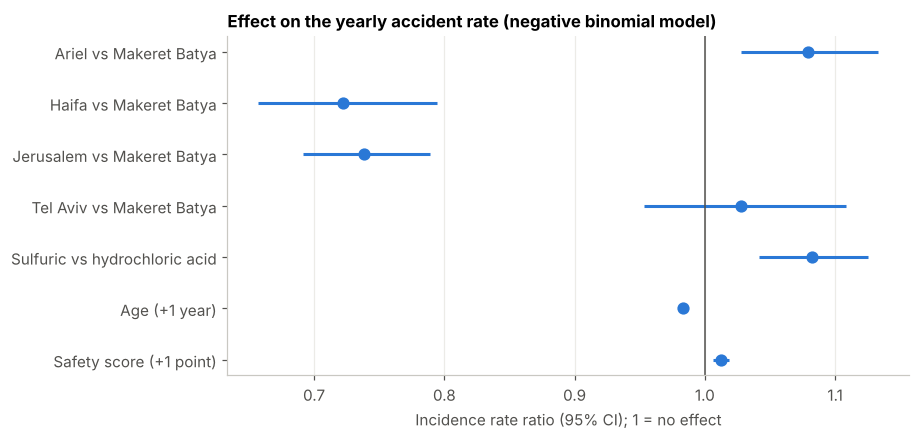

In [5]:
negbin = smf.negativebinomial(FORMULA, df, offset=df.log_years).fit(disp=0, maxiter=200)
lr_stat = 2 * (negbin.llf - poisson.llf)
print(f"alpha = {negbin.params['alpha']:.3f} | AIC Poisson {poisson.aic:,.0f} vs negative binomial {negbin.aic:,.0f} "
      f"| likelihood-ratio statistic {lr_stat:,.0f}")

ci = negbin.conf_int().drop("alpha")
irr = pd.DataFrame({"IRR": np.exp(negbin.params.drop("alpha")), "low": np.exp(ci[0]), "high": np.exp(ci[1]),
                    "p-value": negbin.pvalues.drop("alpha")}).drop("Intercept")
irr.index = ["Ariel vs Makeret Batya", "Haifa vs Makeret Batya", "Jerusalem vs Makeret Batya",
             "Tel Aviv vs Makeret Batya", "Sulfuric vs hydrochloric acid", "Age (+1 year)", "Safety score (+1 point)"]
display(irr.style.format({"IRR": "{:.3f}", "low": "{:.3f}", "high": "{:.3f}", "p-value": "{:.4f}"}))

plot = irr.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
y_pos = np.arange(len(plot))
ax.errorbar(plot.IRR, y_pos, xerr=[plot.IRR - plot.low, plot.high - plot.IRR], fmt="o", color=BLUE,
            ecolor=BLUE, elinewidth=2, capsize=0, markersize=7)
ax.axvline(1, color=MUTED, lw=1)
ax.set_yticks(y_pos, plot.index)
ax.set(xlabel="Incidence rate ratio (95% CI); 1 = no effect",
       title="Effect on the yearly accident rate (negative binomial model)")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "03_incidence_rate_ratios.png"); plt.show()

**Reading.** The negative binomial model fits far better (AIC falls by about 8,800). Coefficients are shown as **incidence rate ratios**: the multiplier on the yearly accident rate.

- **Factory** matters most. Workers in Haifa and Jerusalem have about 26% to 28% fewer accidents per year than in Makeret Batya, and workers in Ariel about 8% more. Tel Aviv is not significantly different.
- **Sulfuric acid** is associated with an 8% higher rate than hydrochloric acid.
- **Age**: each additional year lowers the rate by about 1.6%, so a worker 10 years older has about 15% fewer accidents per year.
- **Safety score** has a small positive effect: about 1.2% more accidents per point, or about 13% between the lowest and highest score.

## 3.5 Testing the offset assumption

Using `log(years)` as an offset assumes the yearly accident rate is constant over a worker's tenure. This can be tested by estimating its coefficient instead of fixing it at 1.

In [6]:
free = smf.negativebinomial(FORMULA + " + log_years", df).fit(disp=0, maxiter=200)
low, high = free.conf_int().loc["log_years"]
print(f"Estimated coefficient of log(years): {free.params['log_years']:.3f} (95% CI {low:.3f} to {high:.3f})")

Estimated coefficient of log(years): 0.942 (95% CI 0.909 to 0.974)


**Reading.** The estimate is 0.94, and its confidence interval excludes 1. Accidents grow slightly less than proportionally with time in the factory: the yearly rate falls a little as workers gain experience. The offset is a reasonable approximation, but the original analysis stated that experience *increases* accidents. That was an artifact of the offset, which forces accidents to grow with time. The data actually suggests the opposite effect on the yearly rate.

## 3.6 The safety score paradox

A higher safety test score is associated with *more* accidents. Is that because riskier workplaces produce higher scores?

In [7]:
print("Mean safety score by factory:", df.groupby("factory", observed=True).safety_score.mean().round(2).to_dict())
print("Mean safety score by chemical:", df.groupby("chemical", observed=True).safety_score.mean().round(2).to_dict())
print("Correlation with age:", round(df.safety_score.corr(df.age), 3), "| with years in factory:", round(df.safety_score.corr(df.years_in_factory), 3))

Mean safety score by factory: {'Makeret_Batya': 5.0, 'Ariel': 4.95, 'Haifa': 5.08, 'Jerusalem': 4.84, 'Tel_Aviv': 5.06}
Mean safety score by chemical: {'Hydrochloric_acid': 5.02, 'Sulfuric_Acid': 4.93}
Correlation with age: 0.005 | with years in factory: -0.009


**Reading.** The original analysis suggested that workers in more dangerous environments receive more training and score higher. The data does not support that explanation: the average score is almost identical across factories and chemicals, and it is unrelated to age or tenure.

A more plausible explanation is **reverse causality**. The accident count is cumulative over a worker's whole tenure, while the test score is a single measurement. If workers who had accidents were sent to extra safety training, they would score higher *because* of their accidents. Testing this would need the date of each test and each accident. Either way, the effect is small and the data cannot show that training causes accidents.

## Summary

| Question | Answer |
|---|---|
| Is Poisson appropriate? | No. All four checks show overdispersion (dispersion ratio 3.4) |
| Final model | Negative binomial with a log(years) offset; AIC 45,883 vs 54,658 for Poisson |
| Strongest effects | Haifa and Jerusalem about 26% to 28% fewer accidents per year; sulfuric acid +8%; age −1.6% per year |
| Offset assumption | Approximately holds; the yearly rate declines slightly with tenure (coefficient 0.94) |
| Safety score | Small positive association; not explained by factory or chemical, likely reverse causality |